# Introduction

This notebook walks through the production of Fig. S03, which shows distributions of the difference in the magnitude of the Stokes drift between WW3-LVWD&CUR and WW3-NOXYZ, where XYZ stands for the model with a mechanism disabled, as well as relative statistics.

## Imports

In [18]:
from pathlib import Path
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew

plt.rcdefaults()
plt.style.use("../src/paper.mplstyle")

# Data

In [3]:
data_path = Path('../data/regridded/')

In [5]:
ww3_lvwd_cur = xr.open_zarr(data_path / 'lvwd_cur.zarr', consolidated=False)

ww3_noref = xr.open_zarr(data_path / 'noref.zarr', consolidated=False)
ww3_nocrt = xr.open_zarr(data_path / 'nocrt.zarr', consolidated=False)
ww3_norel = xr.open_zarr(data_path / 'norel.zarr', consolidated=False)
ww3_noadv = xr.open_zarr(data_path / 'noadv.zarr', consolidated=False)

# Extracting Variables

In [6]:
uuss_lvwd_cur, vuss_lvwd_cur = ww3_lvwd_cur.uuss, ww3_lvwd_cur.vuss

uuss_noref, vuss_noref = ww3_noref.uuss, ww3_noref.vuss
uuss_nocrt, vuss_nocrt = ww3_nocrt.uuss, ww3_nocrt.vuss
uuss_norel, vuss_norel = ww3_norel.uuss, ww3_norel.vuss
uuss_noadv, vuss_noadv = ww3_noadv.uuss, ww3_noadv.vuss

In [7]:
ww3_lvwd_cur.close(); del ww3_lvwd_cur
ww3_noref.close(); del ww3_noref
ww3_nocrt.close(); del ww3_nocrt
ww3_norel.close(); del ww3_norel
ww3_noadv.close(); del ww3_noadv

# Computing magnitudes

In [8]:
def mag(u,v):
    return np.hypot(u,v)

In [9]:
Us_lvwd_cur = mag(uuss_lvwd_cur, vuss_lvwd_cur)

Us_noref = mag(uuss_noref, vuss_noref)
Us_nocrt = mag(uuss_nocrt, vuss_nocrt)
Us_norel = mag(uuss_norel, vuss_norel)
Us_noadv = mag(uuss_noadv, vuss_noadv)

In [10]:
Us_noref_diff = Us_lvwd_cur - Us_noref
Us_nocrt_diff = Us_lvwd_cur - Us_nocrt
Us_norel_diff = Us_lvwd_cur - Us_norel
Us_noadv_diff = Us_lvwd_cur - Us_noadv

In [11]:
Us_lvwd_cur.close(); del Us_lvwd_cur
Us_noref.close(); del Us_noref
Us_nocrt.close(); del Us_nocrt
Us_norel.close(); del Us_norel
Us_noadv.close(); del Us_noadv

# Plotting Distributions

First, we flatten the arrays from their (x, y, time) grid.

In [ ]:
noref_flat = Us_noref_diff.values.ravel()
nocrt_flat = Us_nocrt_diff.values.ravel()
norel_flat = Us_norel_diff.values.ravel()
noadv_flat = Us_noadv_diff.values.ravel()

We save the differences in a dictionary and multiple by 100 to change their units to cm/s to becomes more interperatable.

In [24]:
diffs = {
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOREF}$": noref_flat * 100,
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOCRT}$": nocrt_flat * 100,
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOREL}$": norel_flat * 100,
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOADV}$": noadv_flat * 100,
}

We now concatinate all the flattened arrays and use the range of all differences to find common bin edges to make the plots interinterperetable.

In [ ]:
all_vals = np.concatenate([
    noref_flat,
    nocrt_flat,
    norel_flat,
    noadv_flat,
]) * 100

xmin, xmax = np.percentile(all_vals, [0.1, 99.9])
xmax_abs = max(abs(xmin), abs(xmax))

bins = np.linspace(-xmax_abs, xmax_abs, 81)

We assign the colors for each mechanism similar to other plots.

In [25]:
colors = {
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOREF}$": "darkblue",
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOCRT}$": "royalblue",
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOREL}$": "goldenrod",
    r"$U_\mathrm{s, LVWD&CUR} - U_\mathrm{s, NOADV}$": "blue",
}

We can now plot the distributions. In the `for` loop, statistics are computed: the mean, standard deviation, and skew. The mean is plotted as a vertical line and the rest of the summary statistics in a box.

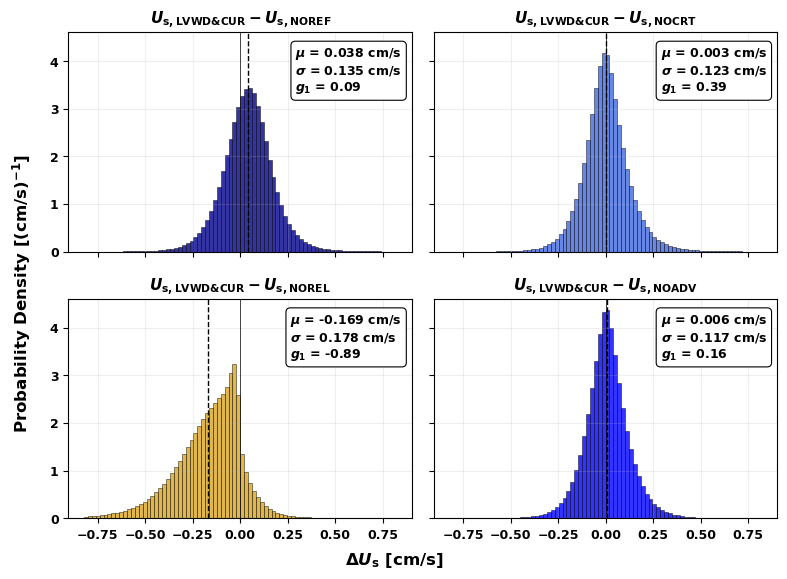

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(8, 6),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()

for ax, (name, vals) in zip(axes, diffs.items()):

    mean = np.mean(vals)
    std = np.std(vals)
    skewness = skew(vals)

    ax.hist(
        vals,
        bins=bins,
        density=True,
        color=colors[name],
        alpha=0.8,
        edgecolor="k",
        linewidth=0.4,
    )

    ax.axvline(
        0,
        color="k",
        linestyle="-",
        linewidth=0.5,
    )

    ax.axvline(
        mean,
        color="k",
        linestyle="--",
        linewidth=1.0,
    )

    # Statistics box
    ax.text(
        0.97,
        0.94,
        (
            rf"$\mu$ = {mean:.3f} cm/s"
            "\n"
            rf"$\sigma$ = {std:.3f} cm/s"
            "\n"
            rf"$g_1$ = {skewness:.2f}"
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        multialignment="left",  # aligns lines inside the box
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="black",
            linewidth=0.8,
            alpha=1.0,
        ),
    )

    ax.set_title(name)
    ax.grid(alpha=0.2)

fig.supxlabel(r"$\Delta U_\mathrm{s}$ [cm/s]", fontweight='bold', fontsize=12, y=0.04)
fig.supylabel(r"Probability Density [(cm/s)$^{-1}$]", fontweight='bold', fontsize=12, x=0.02)

plt.tight_layout()
plt.show()

In [23]:
fig.savefig(
    '../figures/figS03.png',
    dpi=500,
    bbox_inches='tight',
    pad_inches=0.1,
)